# 常用统计可视化图表详解

每种图形回答三个问题：**用来做什么**（适用场景）、**怎么看**（解读要点）、**注意什么**（常见误用）。全部示例使用合成数据，可直接运行（仅依赖 numpy / pandas / matplotlib）。

## 目录

| 类别 | 图形 | 回答的问题 |
|---|---|---|
| 分布 | 直方图、KDE、箱线图、小提琴图、ECDF、QQ 图 | 一个变量「长什么样」？ |
| 比较 / 构成 | 条形图、分组/堆叠条形图、饼图 | 谁多谁少？部分与整体？ |
| 趋势 | 折线图、堆叠面积图 | 随时间怎么变？ |
| 关系 | 散点图、热力图、散点图矩阵 | 两个/多个变量是否相关？ |
| 多维 | 雷达图 | 一个对象在多个维度上的轮廓 |
| 陷阱 | 反模式演示 | 怎么避免画出误导性的图 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

rng = np.random.default_rng(42)

# ---- 中文字体（macOS 常见字体逐个尝试）----
_candidates = ['PingFang SC', 'Hiragino Sans GB', 'Arial Unicode MS', 'STHeiti', 'SimHei']
_available = {f.name for f in font_manager.fontManager.ttflist}
_zh = next((f for f in _candidates if f in _available), None)
if _zh:
    plt.rcParams['font.sans-serif'] = [_zh, 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

# ---- 类别色板：固定顺序，不随意换色（顺序本身经过色觉无障碍校验）----
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED, GRID, BASELINE = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'

# 顺序色图：单色浅->深，编码「数值小->大」（热力图等顺序数据用）
SEQ_BLUE = LinearSegmentedColormap.from_list(
    'seq_blue', ['#cde2fb', '#9ec5f4', '#5598e7', '#2a78d6', '#184f95', '#0d366b'])
# 发散色图：蓝 <-> 灰 <-> 红，编码「低于中性 / 中性 / 高于中性」（相关系数、差值用）
DIV_BR = LinearSegmentedColormap.from_list(
    'div_br', ['#184f95', '#6da7ec', '#f0efec', '#e87b7a', '#991f1e'])

def style_ax(ax, title='', xlabel='', ylabel=''):
    ax.set_title(title, color=INK, fontsize=12, loc='left')
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(BASELINE)

print('中文字体:', _zh)

中文字体: Hiragino Sans GB


## 1. 分布类 —— 一个数值变量「长什么样」

分布是统计可视化的起点：拿到任何一列数值，第一件事就是看它的分布。

### 1.1 直方图（Histogram）

**用来做什么**
- 展示单个连续变量的分布：数据集中在哪、散布多宽、是否对称、有无多峰。

**怎么看**
- X 轴是数值分箱（bin），Y 轴是落在该区间的频数（或占比），柱子越高越多；
- 关注四点：**位置**（峰在哪、中心约多少）、**散布**（范围与离散程度）、**形状**（对称 / 右偏 / 左偏）、**多峰**（多个峰往往意味着数据混合了多种群体，比如两批不同来源的用户）；
- Y 轴必须从 0 开始——人眼按柱长比较，截断会夸大差异。

**注意什么**
- bin 数对形状影响极大：太少糊成一团，太多锯齿噪声。经验起点 `bins=30` 或 `sqrt(样本量)`，多试几档再下结论；
- 直方图对 bin 边界敏感，小样本时改用 KDE 更稳（见 1.2）。

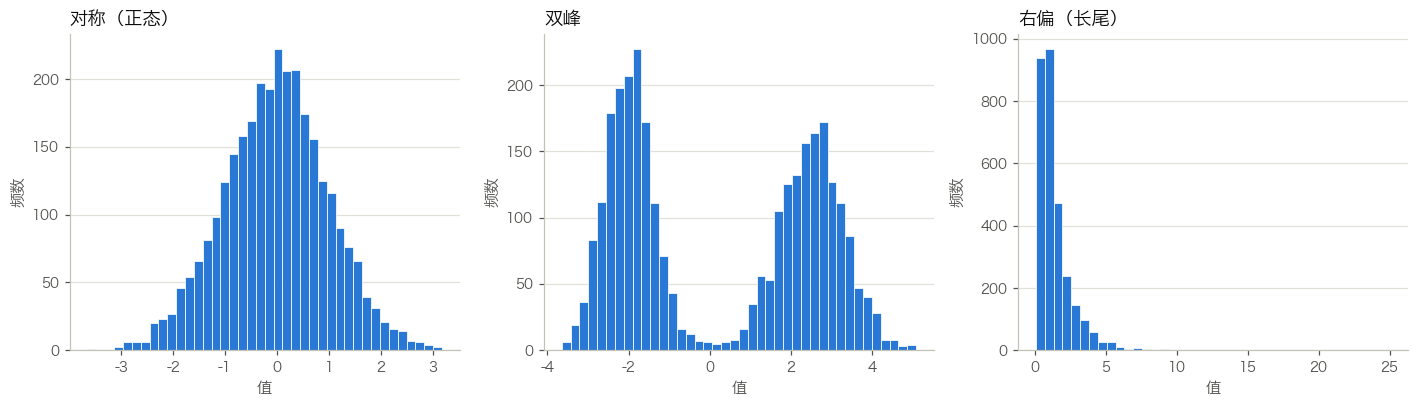

In [2]:
normal = rng.normal(0, 1, 3000)                                     # 对称
bimodal = np.concatenate([rng.normal(-2, 0.6, 1500),
                          rng.normal(2.5, 0.8, 1500)])              # 双峰
skewed = rng.lognormal(0, 0.8, 3000)                                # 右偏（长尾在右）

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, data, name in zip(axes, [normal, bimodal, skewed],
                          ['对称（正态）', '双峰', '右偏（长尾）']):
    ax.hist(data, bins=40, color=C[0], edgecolor='white', linewidth=0.5)
    style_ax(ax, title=name, xlabel='值', ylabel='频数')
plt.tight_layout()
plt.show()

### 1.2 核密度估计图（KDE / Density Plot）

**用来做什么**
- 直方图的平滑版：用连续曲线估计概率密度，特别适合**多条分布叠加比较**（直方图叠在一起会互相遮挡）。

**怎么看**
- 曲线的峰 = 众数的大致位置；曲线越高，该值附近数据越密集；
- 多条曲线比三件事：峰的位置（谁整体更大）、曲线的宽度（谁更分散）、形状（单峰/多峰/偏态）；
- 纵轴是「密度」不是计数，绝对数值不重要，**形状和相对高低才重要**。

**注意什么**
- 平滑带宽（bandwidth）相当于直方图的 bin 宽：太窄出现假峰，太宽抹平真实结构；
- 有天然边界的数据（如评分 1~5、长度 ≥0）KDE 会把密度「溢出」到不可能的区域，读图时留意边界。

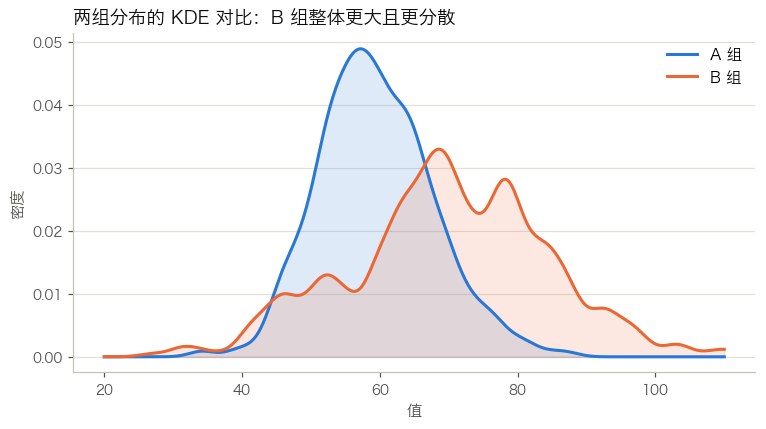

A 组 均值 59.4 / 标准差 8.3 | B 组 均值 69.9 / 标准差 14.5


In [3]:
g1 = rng.normal(60, 8, 500)     # A 组：均值低、集中
g2 = rng.normal(70, 14, 500)    # B 组：均值高、分散

def kde(data, grid, bw=1.8):
    # 高斯核 KDE 手写实现（避免依赖 scipy）
    d = (grid[:, None] - data[None, :]) / bw
    return np.exp(-0.5 * d ** 2).sum(axis=1) / (len(data) * bw * np.sqrt(2 * np.pi))

grid = np.linspace(20, 110, 400)
fig, ax = plt.subplots(figsize=(8, 4))
for data, name, c in [(g1, 'A 组', C[0]), (g2, 'B 组', C[1])]:
    yv = kde(data, grid)
    ax.plot(grid, yv, color=c, lw=2, label=name)
    ax.fill_between(grid, yv, color=c, alpha=0.15)
style_ax(ax, title='两组分布的 KDE 对比：B 组整体更大且更分散', xlabel='值', ylabel='密度')
ax.legend(frameon=False)
plt.show()
print('A 组 均值 %.1f / 标准差 %.1f | B 组 均值 %.1f / 标准差 %.1f'
      % (g1.mean(), g1.std(), g2.mean(), g2.std()))

### 1.3 箱线图（Box Plot / Box-and-Whisker）

**用来做什么**
- 用五个数（最小值、Q1、中位数、Q3、最大值）概括一个分布，最适合**多组并排比较**中位数与离散程度，同时标出离群点。

**怎么看**
- 箱体 = IQR（Q1 到 Q3，覆盖中间 50% 数据），箱内横线 = 中位数；
- 须 = 1.5×IQR 范围内的最远数据点，须之外的点单独画出 = 疑似离群值；
- 中位线在箱内偏上 → 左偏（数据往高处堆积少数极低值）；偏下 → 右偏；
- 箱越长越分散；两组箱的中位线错位明显 → 差异可能真实存在。

**注意什么**
- 只显示概要，**看不出多峰**（双峰分布的箱线图和单峰可能长得一样）；
- 离群点不一定是错误数据，先核实来源再决定是否剔除。

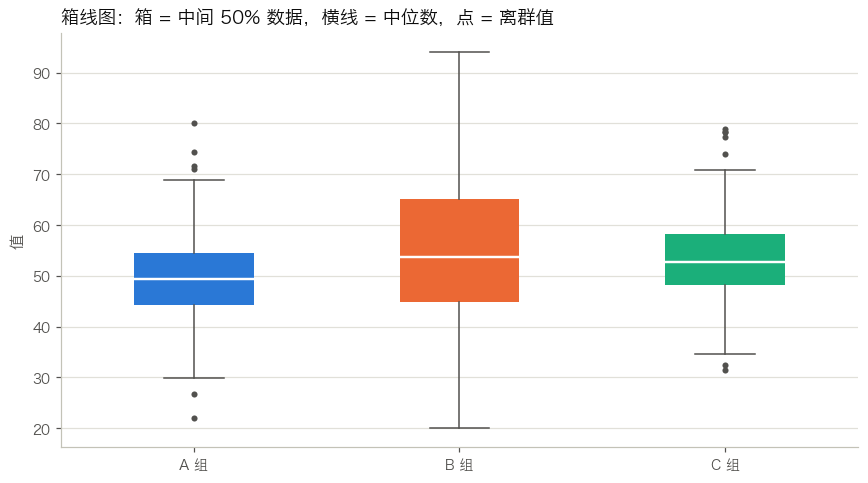

中位数：A 组 49.5 | B 组 53.7 | C 组 52.6


In [4]:
a = np.concatenate([rng.normal(50, 8, 300), [80, 22]])       # 带两个离群点
b = rng.normal(55, 15, 300)                                  # 更分散
c = rng.normal(48, 6, 300) + rng.exponential(6, 300)         # 右偏

fig, ax = plt.subplots(figsize=(8, 4.5))
bp = ax.boxplot([a, b, c], patch_artist=True, widths=0.45,
                medianprops=dict(color='white', lw=1.6),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                flierprops=dict(marker='o', markersize=4,
                                markerfacecolor=MUTED, markeredgecolor='none'),
                boxprops=dict(lw=0))
for patch, col in zip(bp['boxes'], C[:3]):
    patch.set_facecolor(col)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['A 组', 'B 组', 'C 组'])
style_ax(ax, title='箱线图：箱 = 中间 50% 数据，横线 = 中位数，点 = 离群值', ylabel='值')
plt.tight_layout()
plt.show()
print('中位数：A 组 %.1f | B 组 %.1f | C 组 %.1f'
      % (np.median(a), np.median(b), np.median(c)))

### 1.4 小提琴图（Violin Plot）

**用来做什么**
- 箱线图 + 密度曲线的合体：外轮廓是旋转 90° 的密度曲线，既能比较组间概要，又能看出**多峰与偏态**。

**怎么看**
- 越宽的地方 = 该值附近数据越多；最宽处 ≈ 众数；
- 内部常叠加迷你箱线或分位数点（下图黑点为 Q1 / 中位数 / Q3）；
- 中间凹进去的「葫芦形」= 双峰分布——这是它相对箱线图的核心优势。

**注意什么**
- 小样本（每组 < 几十）时轮廓会「虚胖」，形状不可信，退回箱线图；
- 组数很多时显得杂乱，超过 5~6 组建议改用箱线图。

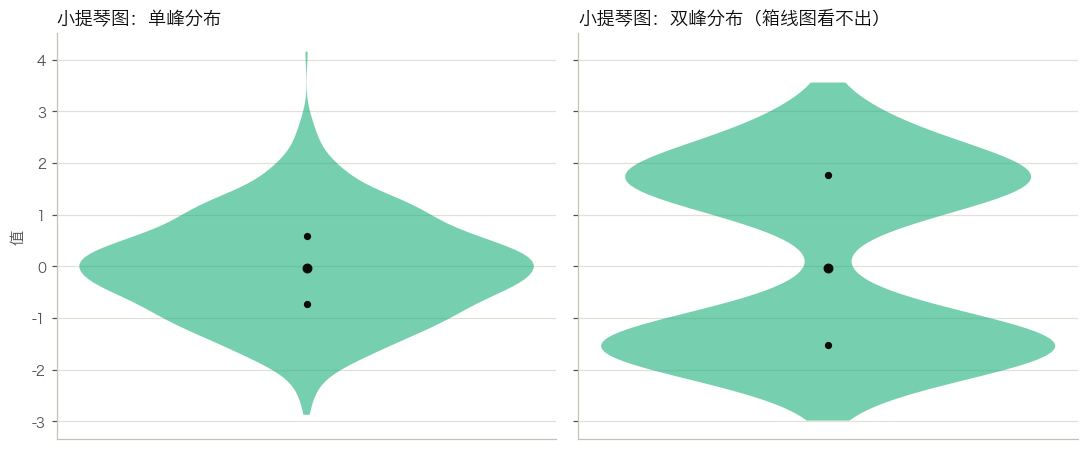

In [5]:
d_norm = rng.normal(0, 1, 800)
d_bimodal = np.concatenate([rng.normal(-1.5, 0.5, 400),
                            rng.normal(1.8, 0.6, 400)])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, data, name in zip(axes, [d_norm, d_bimodal], ['单峰分布', '双峰分布（箱线图看不出）']):
    parts = ax.violinplot(data, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(C[2])
        pc.set_alpha(0.6)
    for q in (25, 50, 75):
        ax.scatter([1], [np.percentile(data, q)], color=INK,
                   s=30 if q == 50 else 14, zorder=3)
    ax.set_xticks([])
    style_ax(ax, title=f'小提琴图：{name}')
axes[0].set_ylabel('值')
plt.tight_layout()
plt.show()

### 1.5 累积分布图（ECDF）

**用来做什么**
- 每个数据点原样呈现、不分箱、不平滑、不失真；直接从图上**读分位数**（P90 在哪），比较两组分布的整体位移与尾部差异。

**怎么看**
- X = 取值，Y =「小于等于该取值的数据占比」；曲线越陡的地方数据越密集（相当于直方图的高柱）；
- 读分位数：找 Y = 0.25 / 0.5 / 0.75 / 0.9 对应的 X 即 P25 / P50 / P75 / P90；
- 两条曲线一条始终在另一条**右侧/下方** → 它的取值系统性更大；曲线交叉 → 分布形状不同。

**注意什么**
- 纵轴永远 0~1；
- 大样本下结论与 KDE 一致，但 ECDF 是无参数方法，不引入平滑假设，写报告时更「硬」。

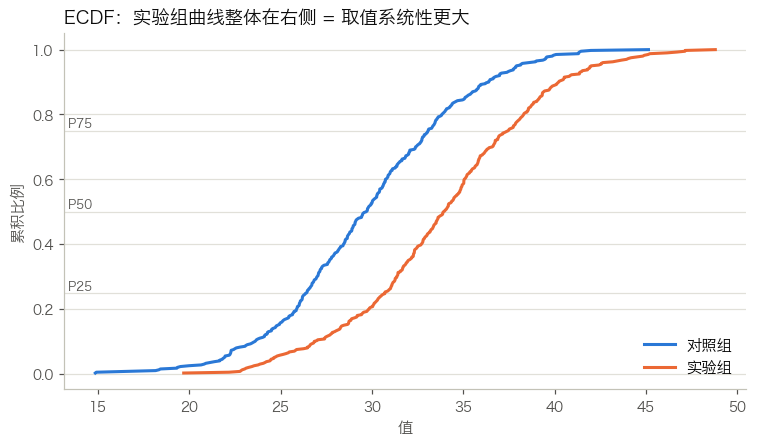

P50：对照组 29.7 | 实验组 34.0


In [6]:
def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

s1 = rng.normal(30, 5, 400)     # 对照组
s2 = rng.normal(34, 5, 400)     # 实验组：整体 +4

fig, ax = plt.subplots(figsize=(8, 4.2))
for data, name, c in [(s1, '对照组', C[0]), (s2, '实验组', C[1])]:
    x, y = ecdf(data)
    ax.plot(x, y, color=c, lw=2, label=name)
for p, txt in [(0.25, 'P25'), (0.5, 'P50'), (0.75, 'P75')]:
    ax.axhline(p, color=GRID, lw=0.8, zorder=0)
    ax.text(ax.get_xlim()[0], p, ' ' + txt, fontsize=8, color=MUTED, va='bottom')
style_ax(ax, title='ECDF：实验组曲线整体在右侧 = 取值系统性更大', xlabel='值', ylabel='累积比例')
ax.legend(frameon=False, loc='lower right')
plt.show()
print('P50：对照组 %.1f | 实验组 %.1f' % (np.median(s1), np.median(s2)))

### 1.6 QQ 图（Quantile-Quantile Plot）

**用来做什么**
- 检查数据是否服从某个理论分布（最常用：正态分布）；回归、t 检验、ANOVA 等方法使用前检查正态性假设的标准手段。

**怎么看**
- 每个点：X = 理论分布的分位数，Y = 样本的分位数；
- 点大致落在 45° 参考线上 → 数据服从该分布；
- 两端同时上翘/下弯 → 尾部比理论更厚（重尾，极端值更多）；
- S 形弯曲 → 偏态（一侧尾长）；只有一端偏离 → 一侧尾部异常。

**注意什么**
- 中间贴线、两端轻微偏离是常态（极值分位数估计噪声大），不要过度解读；
- 样本少时抖动明显，结论要保守。

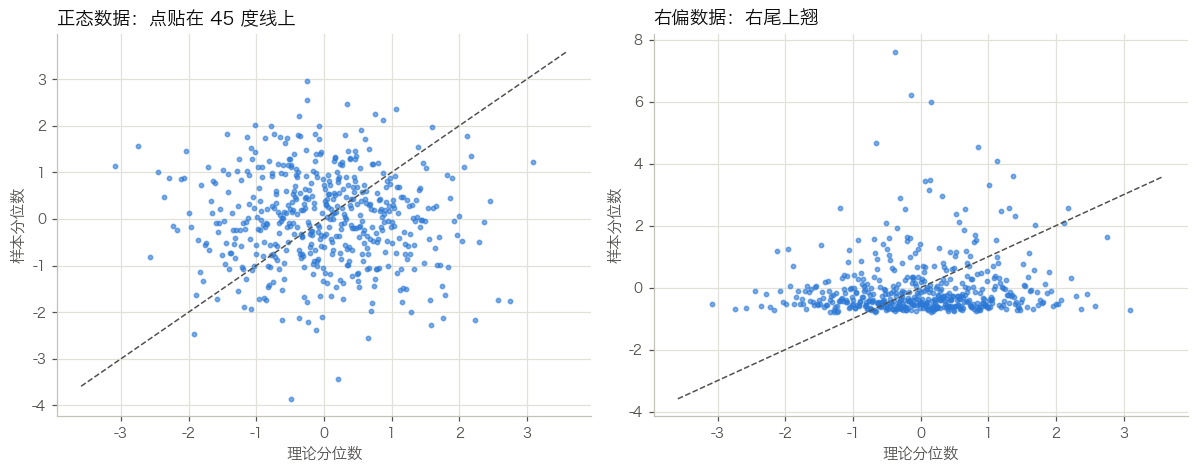

In [7]:
from statistics import NormalDist   # 标准库，替代 scipy.stats.probplot

def qq_points(data):
    n = len(data)
    p = (np.arange(1, n + 1) - 0.5) / n
    theo = np.array([NormalDist().inv_cdf(v) for v in p])
    return theo, (data - data.mean()) / data.std()

nd = rng.normal(0, 1, 500)
sd = rng.lognormal(0, 1, 500)   # 右偏

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, data, name in zip(axes, [nd, sd],
                          ['正态数据：点贴在 45 度线上', '右偏数据：右尾上翘']):
    theo, obs = qq_points(data)
    ax.scatter(theo, obs, s=8, color=C[0], alpha=0.6)
    lim = [theo.min() - 0.5, theo.max() + 0.5]
    ax.plot(lim, lim, color=MUTED, lw=1, ls='--')
    style_ax(ax, title=name, xlabel='理论分位数', ylabel='样本分位数')
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 2. 比较与构成类 —— 谁多谁少、部分与整体

### 2.1 条形图（Bar Chart）

**用来做什么**
- 比较离散类别之间的数值大小（频数、均值、金额……）。类别型变量 + 一个数值，首选条形图。

**怎么看**
- 柱高（或柱长）= 数值，**必须从 0 开始**——人眼按长度比较，截断会夸大差异（第 6 节有演示）；
- 按数值排序（垂直图从高到低、水平图从上到下）远比按原始类别顺序易读；
- 类别名太长或类别太多时用**水平条形图**。

**注意什么**
- 不要在条形图之间连线（折线蕴含「连续变化」的语义）；
- 类别超过 15 个时只展示 Top N + 「其他」。

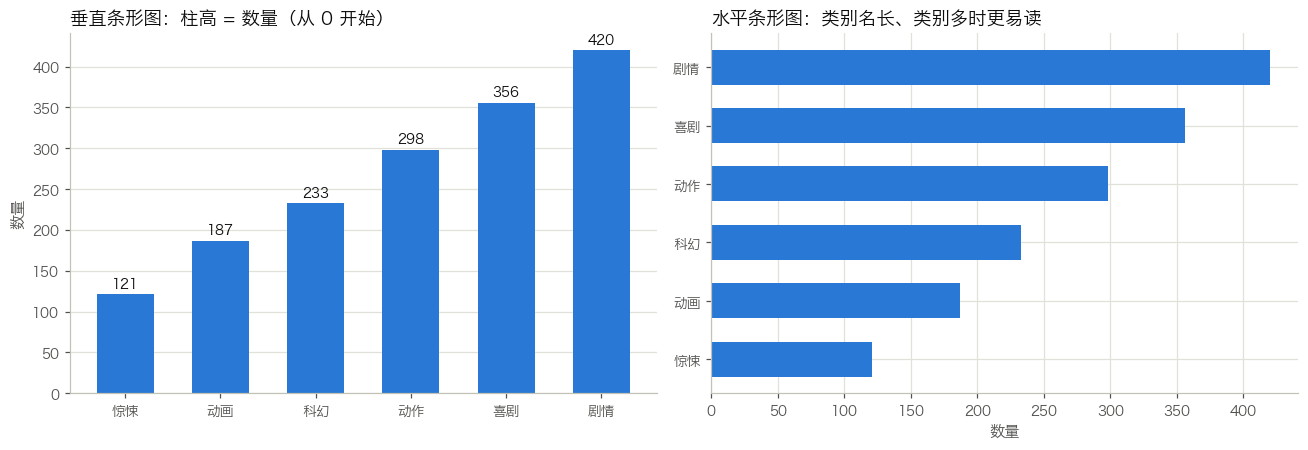

In [8]:
cats = ['剧情', '喜剧', '动作', '科幻', '动画', '惊悚']
vals = np.array([420, 356, 298, 233, 187, 121])
order = np.argsort(vals)   # 升序：水平条形图从下往上画，正好从大到小

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(range(len(vals)), vals[order], color=C[0], width=0.6)
axes[0].set_xticks(range(len(vals)))
axes[0].set_xticklabels([cats[i] for i in order])
for i, v in enumerate(vals[order]):
    axes[0].text(i, v + 8, str(v), ha='center', fontsize=9, color=INK)
style_ax(axes[0], title='垂直条形图：柱高 = 数量（从 0 开始）', ylabel='数量')

axes[1].barh([cats[i] for i in order], vals[order], color=C[0], height=0.6)
axes[1].grid(axis='x', color=GRID, lw=0.8)
axes[1].set_axisbelow(True)
style_ax(axes[1], title='水平条形图：类别名长、类别多时更易读', xlabel='数量')
plt.tight_layout()
plt.show()

### 2.2 分组 / 堆叠 / 100% 堆叠条形图

**用来做什么**
- 两个类别维度的交叉比较（例：各季度 × 各渠道）。同一份数据三种画法，回答的问题不同：
- **分组**：组内谁多谁少；**堆叠**：总量 + 构成；**100% 堆叠**：只看构成比例（不受总量影响）。

**怎么看**
- 分组图：同一组内比较柱高，跨组寻找重复出现的模式；
- 堆叠图：先看总高（总量趋势），再看每段厚度（构成变化）；
- 100% 堆叠：每根柱都归一到 100%，直接比较各部分占比随组的变化。

**注意什么**
- 堆叠段超过 4~5 个就难读；中间段的基线是浮动的，厚度难以精确比较——需要精确比较时改用分组图；
- 图例顺序应与堆叠顺序一致。

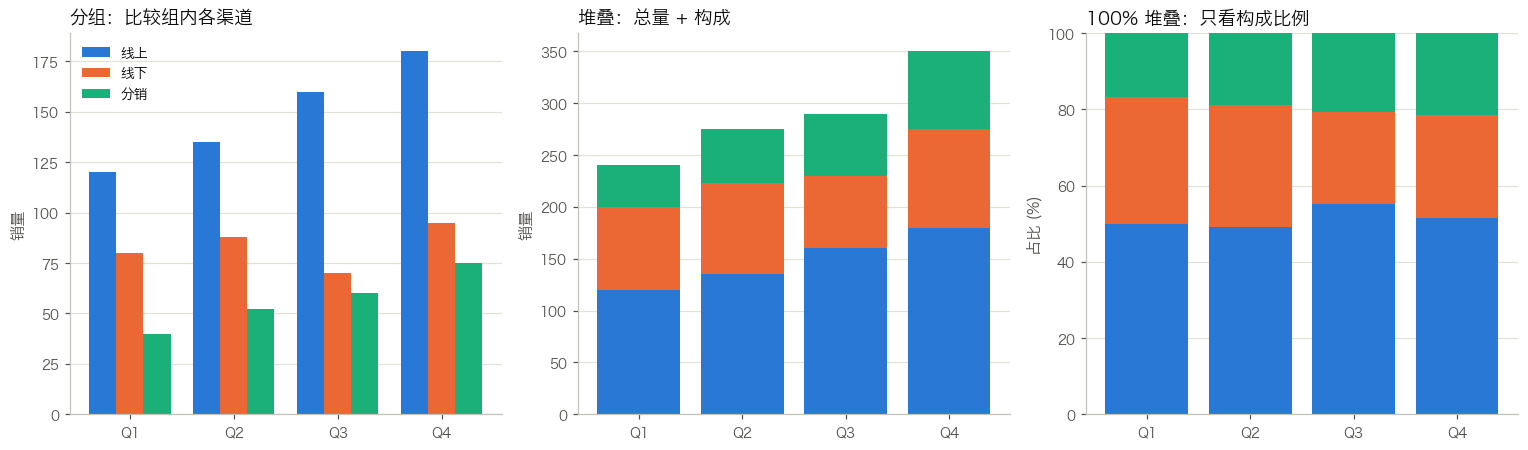

In [9]:
groups = ['Q1', 'Q2', 'Q3', 'Q4']
series = ['线上', '线下', '分销']
raw = np.array([[120, 80, 40], [135, 88, 52], [160, 70, 60], [180, 95, 75]])  # 4 季度 x 3 渠道

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
x = np.arange(len(groups)); w = 0.26
for j, (s, c) in enumerate(zip(series, C[:3])):
    axes[0].bar(x + (j - 1) * w, raw[:, j], width=w, color=c, label=s)
axes[0].set_xticks(x)
axes[0].set_xticklabels(groups)
style_ax(axes[0], title='分组：比较组内各渠道', ylabel='销量')

bottom = np.zeros(len(groups))
for j in range(3):
    axes[1].bar(groups, raw[:, j], bottom=bottom, color=C[j], label=series[j])
    bottom += raw[:, j]
style_ax(axes[1], title='堆叠：总量 + 构成', ylabel='销量')

share = raw / raw.sum(axis=1, keepdims=True) * 100
bottom = np.zeros(len(groups))
for j in range(3):
    axes[2].bar(groups, share[:, j], bottom=bottom, color=C[j], label=series[j])
    bottom += share[:, j]
axes[2].set_ylim(0, 100)
style_ax(axes[2], title='100% 堆叠：只看构成比例', ylabel='占比 (%)')

axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### 2.3 饼图 / 环形图（Pie / Donut Chart）

**用来做什么**
- 展示**少数类别（≤5）**占整体的比例构成，强调「整体中各部分的大小关系」。

**怎么看**
- 看扇形角度 / 弧长：从 12 点钟开始顺时针按大小排列；
- 占比数字直接标在扇区上，不依赖读者估角度。

**注意什么**
- 人眼对角度差远不如对长度差敏感：占比接近（如 24% vs 27%）或类别多于 5 个时，**排序条形图是更好的选择**（下图右）；
- 禁用 3D 饼图（透视会扭曲比例）与多层双环图；
- 环形图 = 中间挖空的饼图，可在中心放合计数字，解读方式相同。

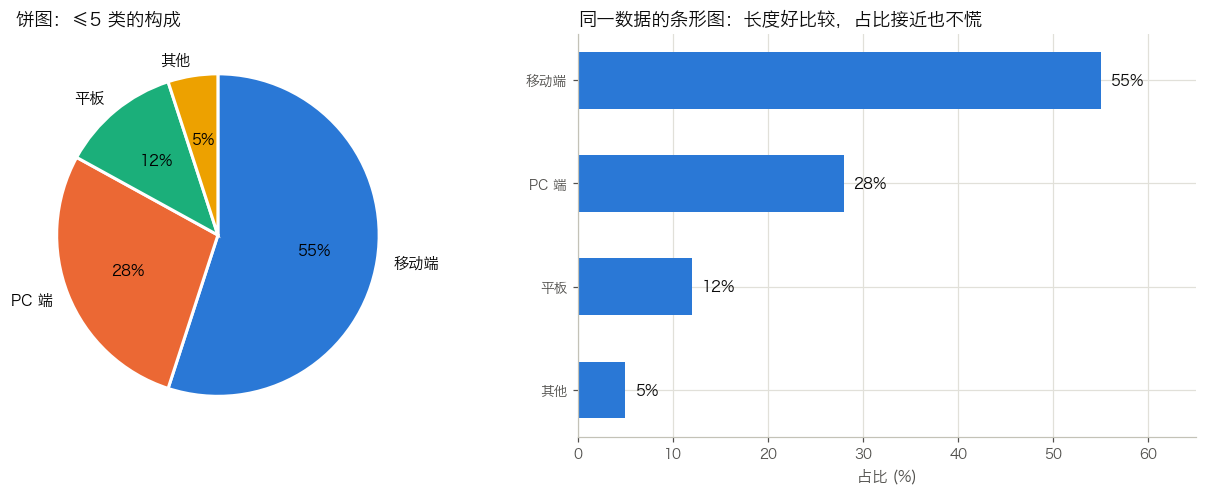

In [10]:
labels = ['移动端', 'PC 端', '平板', '其他']
sizes = [55, 28, 12, 5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].pie(sizes, labels=labels, colors=C[:4], autopct='%.0f%%',
            startangle=90, counterclock=False,
            wedgeprops=dict(edgecolor='white', linewidth=2),
            textprops=dict(fontsize=10))
axes[0].set_title('饼图：≤5 类的构成', color=INK, fontsize=12, loc='left')

axes[1].barh(labels[::-1], sizes[::-1], color=C[0], height=0.55)
for i, v in enumerate(sizes[::-1]):
    axes[1].text(v + 1, i, f'{v}%', va='center', fontsize=10, color=INK)
axes[1].set_xlim(0, 65)
axes[1].grid(axis='x', color=GRID, lw=0.8)
axes[1].set_axisbelow(True)
style_ax(axes[1], title='同一数据的条形图：长度好比较，占比接近也不慌', xlabel='占比 (%)')
plt.tight_layout()
plt.show()

## 3. 趋势类 —— 随时间怎么变

### 3.1 折线图（Line Chart）

**用来做什么**
- 展示连续变量（最常见是时间）上的趋势与波动；多条线对比走势。时间序列的第一选择。

**怎么看**
- 斜率 = 变化速度；水平 = 平稳；关注整体趋势方向、周期性波动、突变点；
- 多条线直接比较高低与交叉（交叉 = 领先关系反转）；
- 可以叠加置信区间带（阴影）表达不确定性，带宽越宽越不确定。

**注意什么**
- Y 轴**不必**从 0 开始（折线看的是变化趋势不是长度），但刻度要诚实、标注清楚；
- 时间间隔不等时必须按时间轴定位点，不能按序号等距画；
- 线超过 4 条会糊，拆成小倍数（small multiples）图。

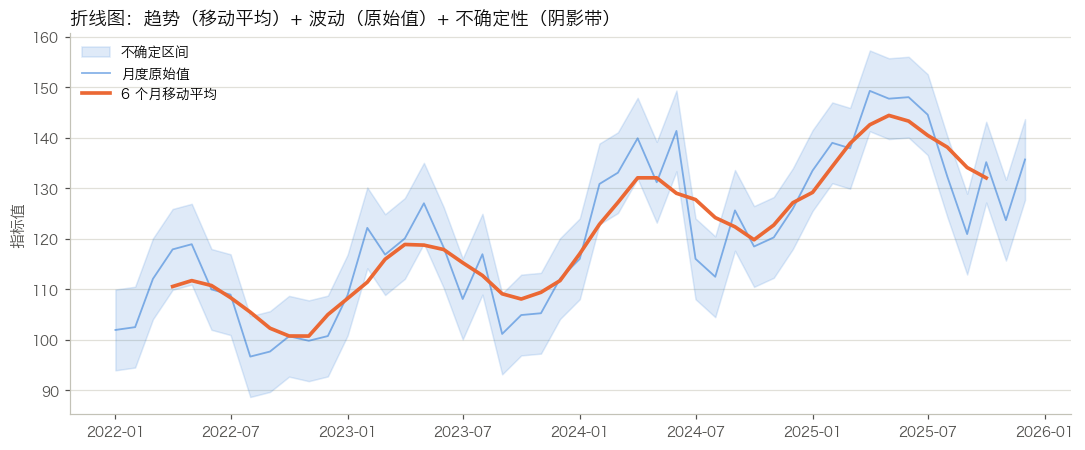

In [11]:
n = 48   # 4 年，按月
t = pd.date_range('2022-01', periods=n, freq='MS')
trend = np.linspace(100, 140, n)                        # 长期趋势
season = 12 * np.sin(np.arange(n) / 12 * 2 * np.pi)     # 年度季节性
noise = rng.normal(0, 5, n)
y = trend + season + noise
roll = pd.Series(y).rolling(6, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.fill_between(t, y - 8, y + 8, color=C[0], alpha=0.15, label='不确定区间')
ax.plot(t, y, color=C[0], lw=1.2, alpha=0.55, label='月度原始值')
ax.plot(t, roll, color=C[1], lw=2.4, label='6 个月移动平均')
style_ax(ax, title='折线图：趋势（移动平均）+ 波动（原始值）+ 不确定性（阴影带）', ylabel='指标值')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### 3.2 堆叠面积图（Stacked Area Chart）

**用来做什么**
- 展示时间上「多部分的构成」如何变化：总量趋势 + 各部分份额演变。

**怎么看**
- 最外层轮廓 = 总量趋势；每一层的**厚度** = 该部分的大小；
- 100% 堆叠面积图（下图右）把每个时间点归一到 100%，只看结构演变，适合各部分规模差异悬殊时。

**注意什么**
- 中间层的基线随下层波动，厚度难以精确比较——「中间那层最近是涨是跌」经常看错，必要时改用 100% 版本或折线图；
- 层超过 4 个就改用折线图或小倍数图。

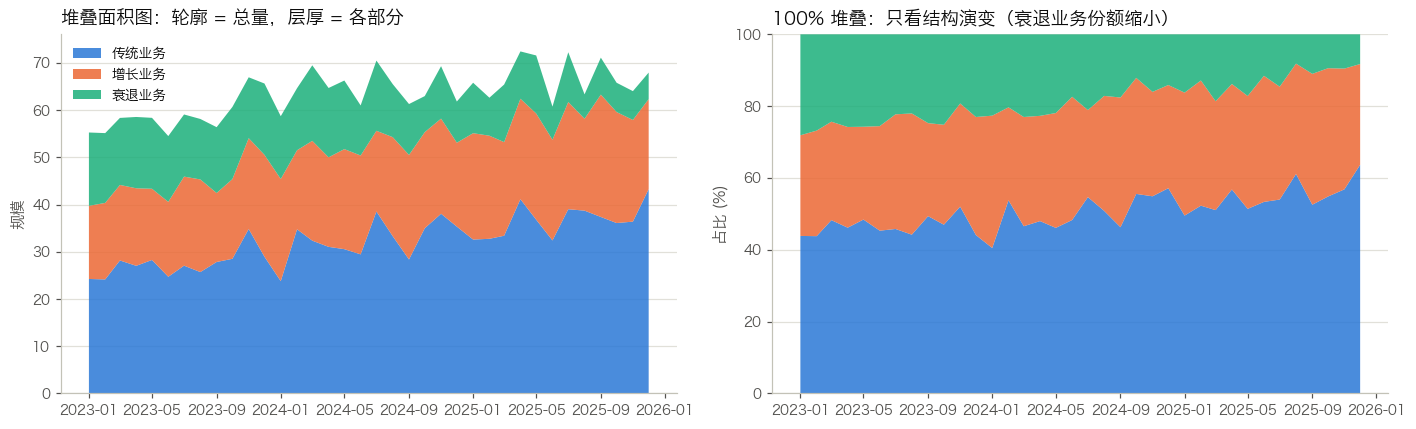

In [12]:
n = 36
t = pd.date_range('2023-01', periods=n, freq='MS')
base = np.linspace(50, 80, n)
comp = np.vstack([
    base * 0.5 + rng.normal(0, 3, n),
    base * 0.3 + rng.normal(0, 2, n),
    base * 0.2 * np.linspace(1.4, 0.4, n) + rng.normal(0, 1.5, n),   # 第三块逐渐萎缩
])
labels = ['传统业务', '增长业务', '衰退业务']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].stackplot(t, comp, labels=labels, colors=C[:3], alpha=0.85)
style_ax(axes[0], title='堆叠面积图：轮廓 = 总量，层厚 = 各部分', ylabel='规模')

share = comp / comp.sum(axis=0) * 100
axes[1].stackplot(t, share, labels=labels, colors=C[:3], alpha=0.85)
axes[1].set_ylim(0, 100)
style_ax(axes[1], title='100% 堆叠：只看结构演变（衰退业务份额缩小）', ylabel='占比 (%)')
axes[0].legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

## 4. 关系类 —— 变量之间是否相关

### 4.1 散点图（Scatter Plot）

**用来做什么**
- 看两个数值变量的关系：方向（正 / 负相关）、强度（点云紧密程度）、形状（线性 / 曲线）、离群点；
- 可以再编码第三个维度：颜色 = 类别、点大小 = 第三个数值（此时称**气泡图**，面积应 ∝ 数值）。

**怎么看**
- 点云从左下到右上 = 正相关，左上到右下 = 负相关，无规律 = 不相关；
- 相关系数 r 量化**线性**强度：|r| > 0.7 强、0.3~0.7 中等、< 0.3 弱；
- r 只度量线性关系：明显的曲线关系 r 可能接近 0——**先画图、再看 r**，顺序不能反。

**注意什么**
- 相关 ≠ 因果：可能都是第三个变量（混淆变量）驱动的，或纯属巧合；
- 数据量大时点会重叠成一坨（overplotting）：加透明度、抽稀、或用六边形分箱；
- 离群点对相关系数影响极大，先看图识别。

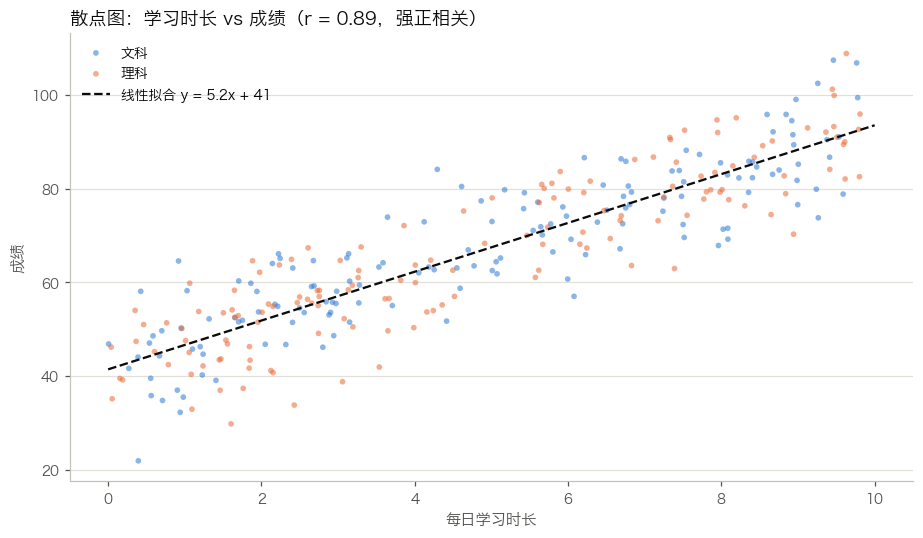

In [13]:
n = 300
study = rng.uniform(0, 10, n)                    # 每日学习时长
score = 40 + 5.5 * study + rng.normal(0, 8, n)   # 成绩 = 基础 + 效应 + 噪声
major = rng.choice(['文科', '理科'], n)

fig, ax = plt.subplots(figsize=(8.5, 5))
for g, c in zip(['文科', '理科'], [C[0], C[1]]):
    m = major == g
    ax.scatter(study[m], score[m], s=14, alpha=0.55, color=c, label=g, edgecolors='none')
k, b = np.polyfit(study, score, 1)
xs = np.linspace(0, 10, 50)
ax.plot(xs, k * xs + b, color=INK, lw=1.5, ls='--',
        label=f'线性拟合 y = {k:.1f}x + {b:.0f}')
r = np.corrcoef(study, score)[0, 1]
style_ax(ax, title=f'散点图：学习时长 vs 成绩（r = {r:.2f}，强正相关）',
         xlabel='每日学习时长', ylabel='成绩')
ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

### 4.2 热力图（Heatmap）

**用来做什么**
- 用颜色编码矩阵数据的整体模式：相关矩阵、两个类别变量交叉的频数 / 占比表（列联表）、时间 × 维度的活跃度等。

**怎么看**
- 颜色深浅 = 数值大小。**顺序数据**（只有大小方向）用单色渐变：浅 = 小、深 = 大（下图左）；
- **发散数据**（围绕某个中性点，如相关系数围绕 0）用发散色图：蓝 = 负、灰 = 中性、红 = 正（下图右）；
- 先扫整体色块格局（哪里成片地高 / 低），再逐格读标注数值。

**注意什么**
- 必须带 colorbar（图例）说明颜色 ↔ 数值的映射；
- 禁用彩虹色（jet/rainbow）：颜色顺序与人眼感知不一致，还会在色带交界处制造假分界；
- 行列顺序可以按聚类或大小重排，让块状模式更明显。

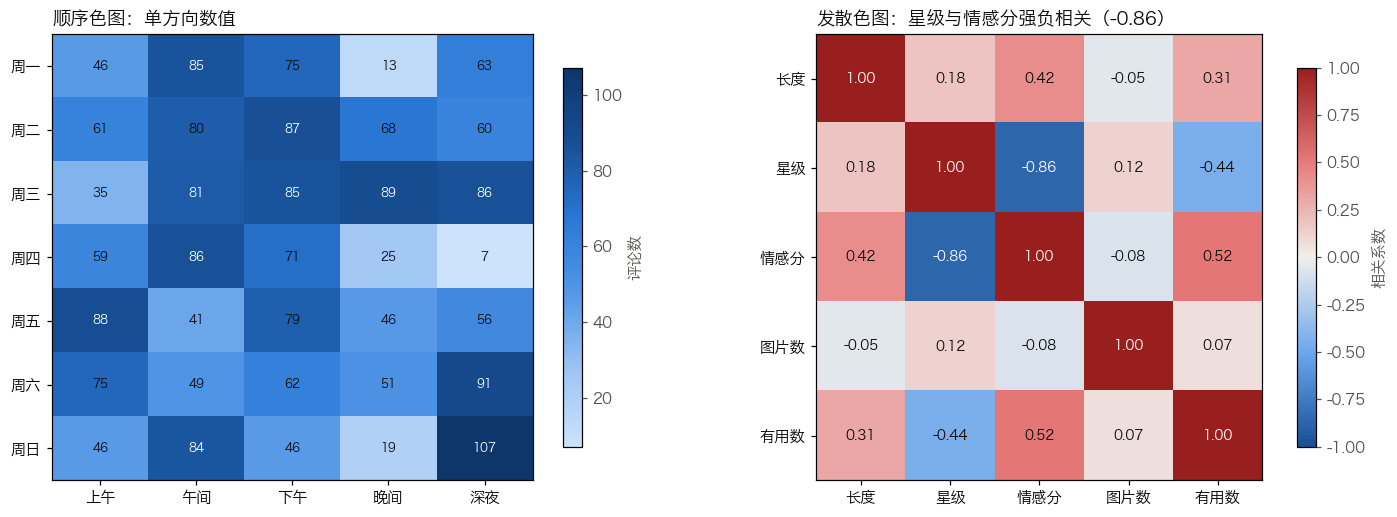

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.15]})

# 左：顺序色图 —— 一周 x 时段的评论量（单方向数值：浅 = 少，深 = 多）
hours = ['上午', '午间', '下午', '晚间', '深夜']
days = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']
act = rng.integers(5, 90, (7, 5)).astype(float)
act[4:, 3:] *= 1.6                       # 周末晚上更活跃
im0 = axes[0].imshow(act, cmap=SEQ_BLUE, aspect='auto')
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(hours)
axes[0].set_yticks(range(7)); axes[0].set_yticklabels(days)
for i in range(7):
    for j in range(5):
        axes[0].text(j, i, int(act[i, j]), ha='center', va='center', fontsize=8,
                     color='white' if act[i, j] > 80 else INK)
cb0 = fig.colorbar(im0, ax=axes[0], shrink=0.85)
cb0.set_label('评论数', color=MUTED)
cb0.ax.tick_params(colors=MUTED)
axes[0].set_title('顺序色图：单方向数值', color=INK, fontsize=12, loc='left')

# 右：发散色图 —— 相关系数矩阵（围绕 0：蓝 = 负，红 = 正，灰 = 无关）
cols = ['长度', '星级', '情感分', '图片数', '有用数']
corr = np.array([
    [ 1.00,  0.18,  0.42, -0.05,  0.31],
    [ 0.18,  1.00, -0.86,  0.12, -0.44],
    [ 0.42, -0.86,  1.00, -0.08,  0.52],
    [-0.05,  0.12, -0.08,  1.00,  0.07],
    [ 0.31, -0.44,  0.52,  0.07,  1.00],
])
im1 = axes[1].imshow(corr, cmap=DIV_BR, vmin=-1, vmax=1)
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(cols)
axes[1].set_yticks(range(5)); axes[1].set_yticklabels(cols)
for i in range(5):
    for j in range(5):
        v = corr[i, j]
        axes[1].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                     color='white' if abs(v) > 0.6 else INK)
cb1 = fig.colorbar(im1, ax=axes[1], shrink=0.85)
cb1.set_label('相关系数', color=MUTED)
cb1.ax.tick_params(colors=MUTED)
axes[1].set_title('发散色图：星级与情感分强负相关（-0.86）', color=INK, fontsize=12, loc='left')

plt.tight_layout()
plt.show()

### 4.3 散点图矩阵（Scatter Matrix / Pairs Plot）

**用来做什么**
- 一口气看 4~6 个数值变量**两两之间**的关系（EDA 初筛相关变量的利器）。

**怎么看**
- 对角线 = 各变量自己的分布（直方图）；非对角 = 对应两个变量的散点图；
- (i, j) 与 (j, i) 关于对角线镜像；
- 重点找「点云有形状」的格子（斜带、曲线、分簇），那两列变量值得单独深入。

**注意什么**
- 格子数按变量数平方增长，变量超过 6 个图就没法看了，先挑候选变量。

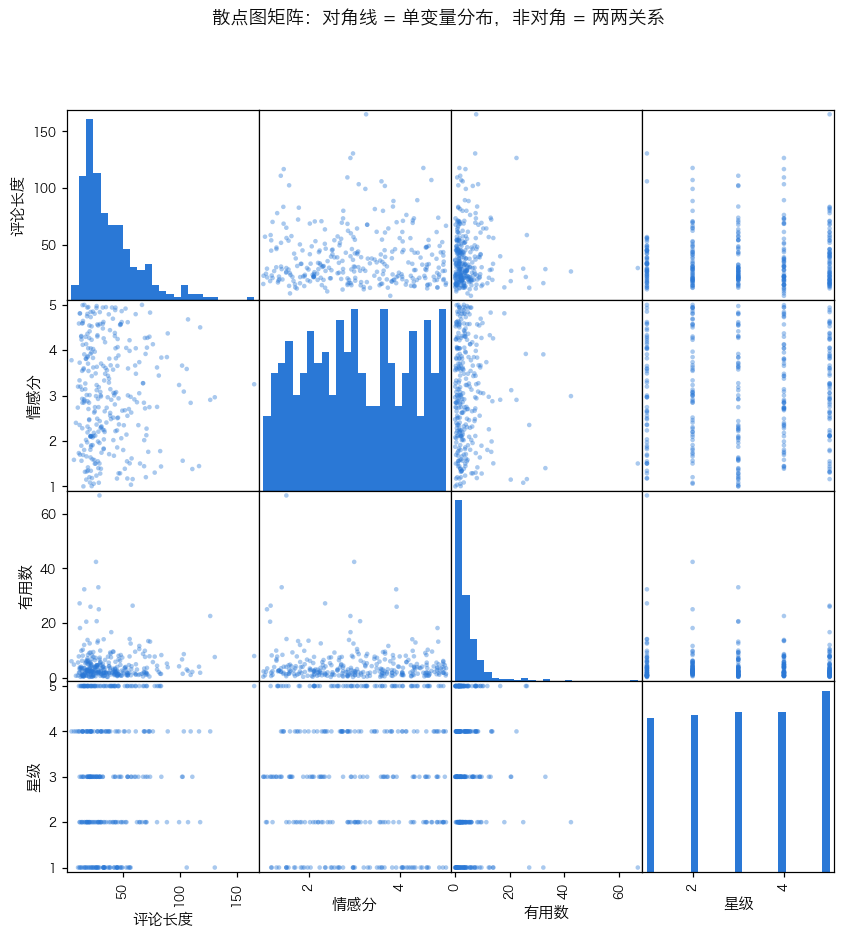

In [15]:
pdf = pd.DataFrame({
    '评论长度': rng.lognormal(3.5, 0.6, 300),
    '情感分': rng.uniform(1, 5, 300),
    '有用数': rng.lognormal(1, 1, 300),
    '星级': rng.integers(1, 6, 300).astype(float),
})
axes = pd.plotting.scatter_matrix(pdf, figsize=(9, 9), diagonal='hist',
                                  color=C[0], alpha=0.4,
                                  hist_kwds={'bins': 25, 'color': C[0]})
plt.suptitle('散点图矩阵：对角线 = 单变量分布，非对角 = 两两关系', color=INK)
plt.show()

## 5. 多维概览 —— 雷达图

### 5.1 雷达图（Radar / Spider Chart）

**用来做什么**
- 展示一个对象在多个维度（3~8 个）上的「能力轮廓」，适合**少数几个对象**的整体形状对比。

**怎么看**
- 每个轴一个维度，顶点离圆心越远得分越高；比较的是**形状差异**（哪个方向凸出），不是多边形面积；
- 轴的起点必须统一且从 0 开始，否则轮廓大小没有意义。

**注意什么**
- 维度顺序会改变多边形形状（相邻维度的组合影响观感），对比时保持顺序一致；
- 维度 > 8 或对象 > 3 时改用分组条形图或热力图——雷达图的辨识度会迅速崩掉；
- 面积大 = 全面强是错觉，一个维度超低也会被「平均」掩盖，逐轴看。

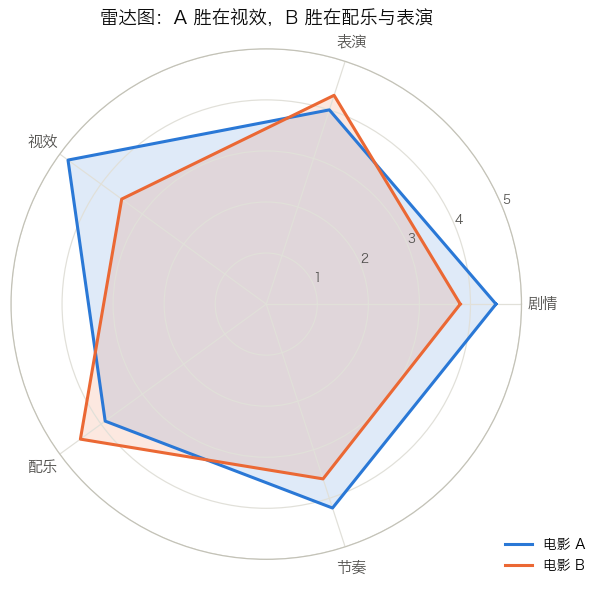

In [16]:
dims = ['剧情', '表演', '视效', '配乐', '节奏']
sA = [4.5, 4.0, 4.8, 3.9, 4.2]
sB = [3.8, 4.3, 3.5, 4.5, 3.6]

ang = np.linspace(0, 2 * np.pi, len(dims), endpoint=False).tolist()
ang += ang[:1]                       # 闭合多边形
sA_c, sB_c = sA + sA[:1], sB + sB[:1]

fig, ax = plt.subplots(figsize=(5.5, 5.5), subplot_kw=dict(polar=True))
for vals_, name, c in [(sA_c, '电影 A', C[0]), (sB_c, '电影 B', C[1])]:
    ax.plot(ang, vals_, color=c, lw=2, label=name)
    ax.fill(ang, vals_, color=c, alpha=0.15)
ax.set_xticks(ang[:-1])
ax.set_xticklabels(dims)
ax.set_ylim(0, 5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1', '2', '3', '4', '5'], fontsize=8, color=MUTED)
ax.grid(color=GRID)
ax.spines['polar'].set_color(BASELINE)
ax.tick_params(colors=MUTED)
ax.set_title('雷达图：A 胜在视效，B 胜在配乐与表演', color=INK, fontsize=12)
ax.legend(frameon=False, fontsize=9, loc='lower right', bbox_to_anchor=(1.15, -0.05))
plt.tight_layout()
plt.show()

## 6. 常见误导与反模式

| 反模式 | 为什么误导 | 正确做法 |
|---|---|---|
| 截断 Y 轴的条形图 | 柱长不再 ∝ 数值，小差异被放大数倍（下图演示） | 条形图 Y 轴从 0 开始 |
| 双 Y 轴图 | 两条线各用一个刻度，交点、斜率、高低都没有意义 | 归一化到同一基准，或拆成两张图 |
| 彩虹色 colormap | 颜色顺序 ≠ 数值感知顺序，色带交界制造假分界 | 顺序数据用单色渐变，发散数据用蓝-灰-红 |
| 3D / 特效图 | 透视扭曲面积与角度，信息增量为零 | 老老实实用 2D |
| 类别过多的饼图 | 角度差肉眼无法分辨 | > 5 类改排序条形图 |
| 把相关当因果 | 混淆变量或巧合都能制造高相关 | 找到因果机制前只说「相关」 |
| 噪声当规律 | 小样本 + 参数调细，随机会画出「形状」 | 检查样本量，多试参数看结论是否稳定 |

下面演示危害最大、也最常见的一个：**截断 Y 轴的条形图**。

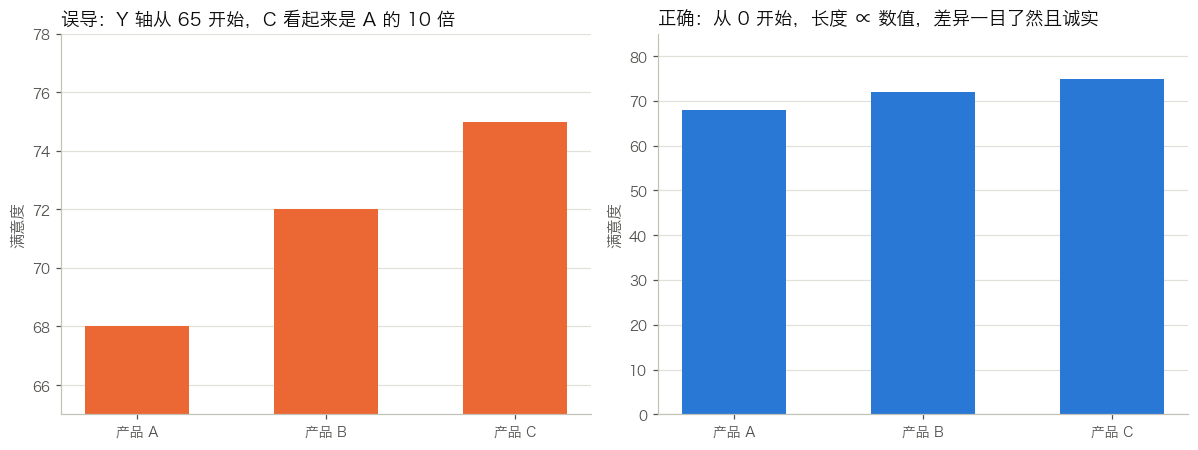

真实比例：A 68% -> B 75% = +10%，但左图的柱长比约为 3.3 倍


In [17]:
vals = [68, 72, 75]   # 满意度：其实只差 10%

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(['产品 A', '产品 B', '产品 C'], vals, color=C[1], width=0.55)
axes[0].set_ylim(65, 78)   # 截断 Y 轴
style_ax(axes[0], title='误导：Y 轴从 65 开始，C 看起来是 A 的 10 倍', ylabel='满意度')

axes[1].bar(['产品 A', '产品 B', '产品 C'], vals, color=C[0], width=0.55)
axes[1].set_ylim(0, 85)
style_ax(axes[1], title='正确：从 0 开始，长度 ∝ 数值，差异一目了然且诚实', ylabel='满意度')
plt.tight_layout()
plt.show()
print('真实比例：A %.0f%% -> B %.0f%% = +%.0f%%，但左图的柱长比约为 %.1f 倍'
      % (vals[0], vals[2], (vals[2] / vals[0] - 1) * 100,
         (vals[2] - 65) / (vals[0] - 65)))

## 7. 快速选图指南

| 你想回答的问题 | 用什么图 |
|---|---|
| 一个数值变量长什么样？ | 直方图 / KDE / 箱线图 |
| 检查正态性假设？ | QQ 图 |
| 直接读分位数、比较两组整体分布？ | ECDF |
| 哪个类别最多 / 最少？ | 排序条形图 |
| 两个类别维度交叉比较？ | 分组 / 堆叠 / 100% 堆叠条形图 |
| 少数类别占整体的比例？ | 饼图（≤5 类），否则条形图 |
| 随时间怎么变？ | 折线图（可加置信区间带） |
| 总量与构成随时间怎么变？ | 堆叠面积图（结构为主用 100% 版本） |
| 两个数值变量是否相关？ | 散点图 + 相关系数 |
| 矩阵数据的整体模式？ | 热力图（顺序数据用单色渐变，发散数据用蓝-灰-红） |
| 多个变量两两关系初筛？ | 散点图矩阵 |
| 单对象多维轮廓对比（少量对象）？ | 雷达图 |

一句话原则：**先想清楚「这张图要回答什么问题」，再选图形形式，最后才是调颜色和样式**——顺序反了就会画出好看但没用的图。